# Experiment 07: symmetric tensor transfer learning curves

Five training recipes at N = 10, 50, 100, 200 and 800 training structures, with one seed (42) each. The training sets are nested, and every run uses the same 50 validation and 150 test structures. All 25 models converged via validation early stopping (300 epochs without improvement); each is evaluated using its validation-selected checkpoint.

The N100 direct training, full fine-tuning and ELoRA points are Experiments 01, 05 and 06. The remaining 22 runs were trained on ARC HTC (initial array job 9456723, followed by in-place resumes for the three N800 runs that hit the 12-hour wall time and the five NMR-head-only runs with a raised epoch ceiling so all five converged cleanly).

Headline Soprano parameters extracted from the reconstructed `0e + 2e` tensors and compared with the original DFT tensors:
- **Isotropic shielding σiso** (ppm)
- **Absolute Haeberlen anisotropy |Δσ|** (ppm) — continuous across η ≈ 1, avoiding axis-label sign-flip discontinuities
- **Asymmetry η** (dimensionless)

Maryland **skew κ** (smooth signed tensor-shape check) and **signed Haeberlen anisotropy Δσ** (with opposite-sign flip rates) are included below as secondary diagnostics. All atoms are retained with no clipping, filtering or sign alignment.

**Balanced error** is ½(MSE_Si / var_Si + MSE_O / var_O) for each parameter, where each variance is that parameter's DFT variance over the full 800-structure training pool. It weights the two elements equally, uses no validation or test labels, and equals 1.0 for a model that predicts the training-pool mean.

In [1]:
from pathlib import Path
import subprocess
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
from analysis_helpers.learning_curves import (load_curves, run_summary, rmse_table,
                                              sign_flip_table, plot_parameter_curves, save_figure)

DATA = ROOT / 'experiments/07-SymmetricTensor-LearningCurves-data'
FIGURES = DATA / 'figures'
# Re-run inference for any run without a cached prediction. Does not train.
RECOMPUTE = False
if RECOMPUTE:
    subprocess.run([sys.executable, str(ROOT / 'scripts/evaluate_experiment07.py')],
                   check=True, cwd=ROOT)
curves, source = load_curves(ROOT, DATA)
pd.set_option('display.precision', 4)
print('Metrics from', source)

Metrics from metrics-all-parameters.csv


## Runs

`Best epoch` is the validation-selected checkpoint. `Last epoch` is where early stopping (300 epochs without improvement) ended the run. All 22 new Experiment 07 runs stopped cleanly via early stopping (`Last epoch = Best epoch + 300`). The reused N100 runs from Experiments 01, 05 and 06 have no Experiment 07 audit record, so their epochs are blank.

In [2]:
display(run_summary(ROOT, DATA))

,Method,N,Run,Best epoch,Last epoch
0,Full fine-tuning,10,07-SymmetricTensor-full-N10-9457374,563.0,863.0
1,Full fine-tuning,50,07-SymmetricTensor-full-N50-9457512,346.0,646.0
2,Full fine-tuning,100,05-SymmetricTensor-FullFineTune-N100-9274115,NaN,NaN
3,Full fine-tuning,200,07-SymmetricTensor-full-N200-9457613,227.0,527.0
4,Full fine-tuning,800,07-SymmetricTensor-full-N800-9460883,352.0,652.0
5,ELoRA,10,07-SymmetricTensor-elora-N10-9460884,294.0,594.0
6,ELoRA,50,07-SymmetricTensor-elora-N50-9462819,232.0,532.0
7,ELoRA,100,06-SymmetricTensor-ELoRA-N100-R4-9274116,NaN,NaN
8,ELoRA,200,07-SymmetricTensor-elora-N200-9464322,364.0,664.0
9,ELoRA,800,07-SymmetricTensor-elora-N800-9464937,219.0,519.0


## Isotropic shielding σiso

Test RMSE in ppm for Si and O, and the element-balanced standardised MSE. Both axes are logarithmic.

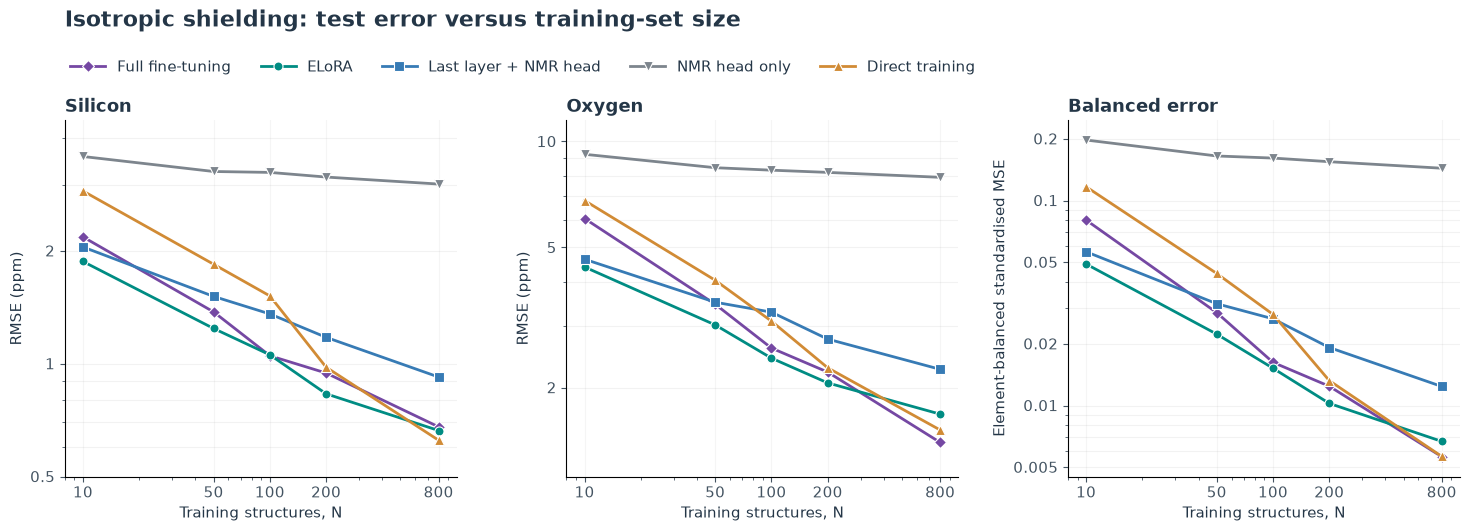

N                                  10      50      100     200     800
Element  Method                                                       
Si       Full fine-tuning       2.1786  1.3745  1.0501  0.9443  0.6785
         ELoRA                  1.8734  1.2416  1.0562  0.8312  0.6634
         Last layer + NMR head  2.0480  1.5118  1.3575  1.1758  0.9214
         NMR head only          3.5704  3.2560  3.2378  3.1468  3.0143
         Direct training        2.8888  1.8421  1.5163  0.9787  0.6250
O        Full fine-tuning       6.0433  3.4510  2.5901  2.2138  1.3975
         ELoRA                  4.4014  3.0136  2.4252  2.0628  1.6814
         Last layer + NMR head  4.6308  3.4961  3.2760  2.7469  2.2540
         NMR head only          9.1974  8.4250  8.2895  8.1703  7.9113
         Direct training        6.7979  4.0362  3.0895  2.2770  1.5159
balanced Full fine-tuning       0.0803  0.0284  0.0162  0.0124  0.0056
         ELoRA                  0.0490  0.0223  0.0152  0.0102  0.0067
         Last layer + NMR head  0.0562  0.0314  0.0265  0.0192  0.0124
         NMR head only          0.1973  0.1649  0.1611  0.1546  0.1437
         Direct training        0.1167  0.0441  0.0278  0.0132  0.0056

In [3]:
fig = plot_parameter_curves(curves, 'isotropy', 'test')
save_figure(fig, FIGURES, 'test-isotropy-learning-curves')
plt.show()
display(rmse_table(curves, 'isotropy', 'test'))

## Absolute shielding anisotropy |Δσ|

Primary tensor-shape magnitude metric. Taking `|Δσ|` removes the Haeberlen axis-label discontinuity near η ≈ 1 (where a tiny prediction error can swap which principal axis is labelled `zz` and flip the sign of signed Δσ). Test RMSE in ppm for Si and O, and element-balanced standardised MSE.

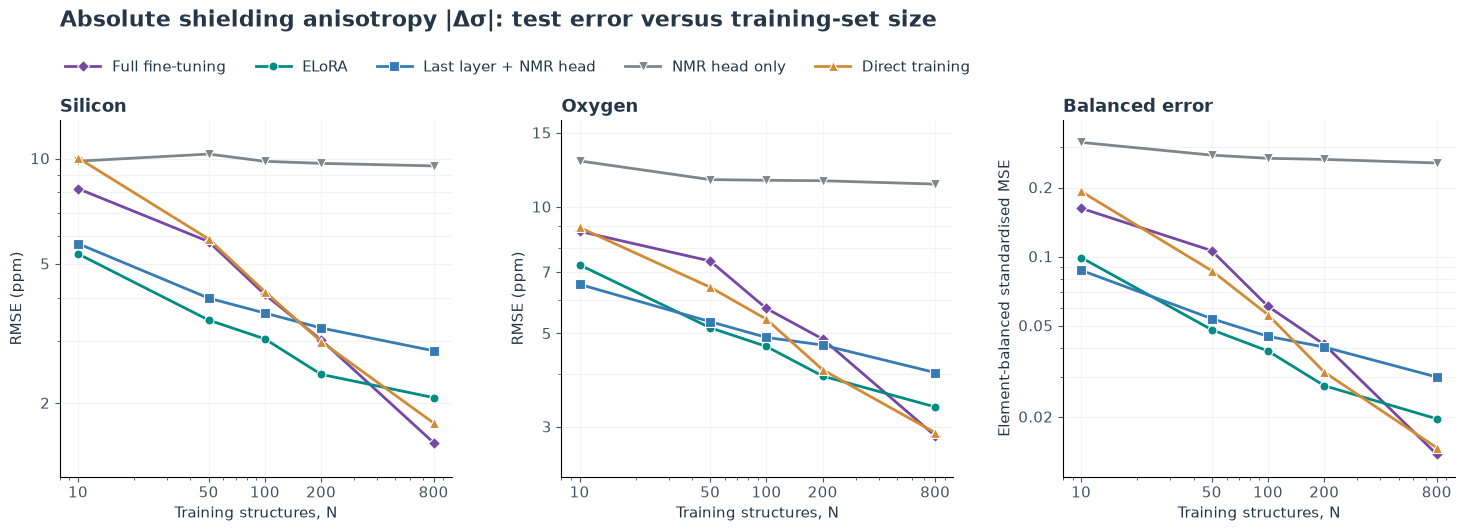

N                                   10       50       100      200      800
Element  Method                                                            
Si       Full fine-tuning        8.2053   5.7908   4.0877   3.0325   1.5412
         ELoRA                   5.3431   3.4547   3.0510   2.4161   2.0737
         Last layer + NMR head   5.7151   3.9912   3.6177   3.2789   2.8215
         NMR head only           9.8319  10.3026   9.8215   9.6909   9.5297
         Direct training        10.0484   5.8921   4.1653   2.9992   1.7543
O        Full fine-tuning        8.7497   7.4360   5.7333   4.8510   2.8558
         ELoRA                   7.2807   5.1611   4.6571   3.9605   3.3448
         Last layer + NMR head   6.5439   5.3345   4.8941   4.6936   4.0374
         NMR head only          12.8620  11.6115  11.5678  11.5383  11.3289
         Direct training         8.9335   6.4418   5.4058   4.0987   2.9050
balanced Full fine-tuning        0.1626   0.1062   0.0607   0.0414   0.0137
         ELoRA                   0.0991   0.0480   0.0388   0.0274   0.0196
         Last layer + NMR head   0.0872   0.0536   0.0449   0.0403   0.0299
         NMR head only           0.3149   0.2770   0.2683   0.2654   0.2561
         Direct training         0.1924   0.0868   0.0558   0.0314   0.0147

In [4]:
fig = plot_parameter_curves(curves, 'abs_anisotropy', 'test')
save_figure(fig, FIGURES, 'test-abs-anisotropy-learning-curves')
plt.show()
display(rmse_table(curves, 'abs_anisotropy', 'test'))

## Asymmetry η

Test RMSE (dimensionless) for Si and O, and the element-balanced standardised MSE. Both axes are logarithmic.

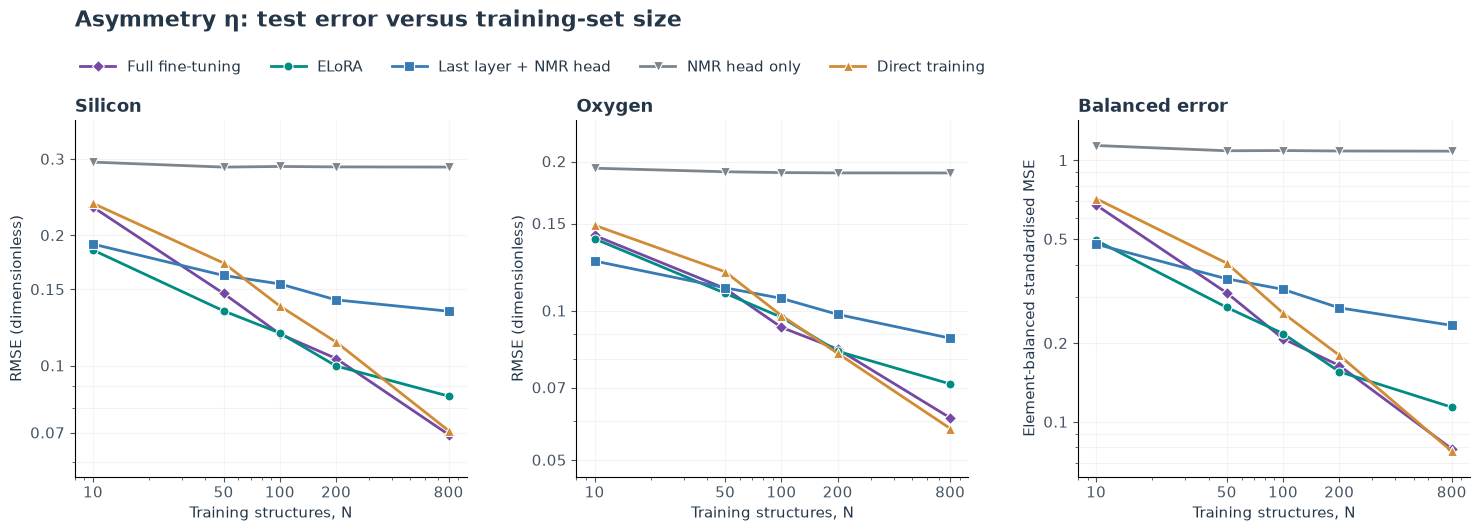

N                                  10      50      100     200     800
Element  Method                                                       
Si       Full fine-tuning       0.2324  0.1468  0.1184  0.1039  0.0693
         ELoRA                  0.1850  0.1338  0.1190  0.0999  0.0851
         Last layer + NMR head  0.1909  0.1616  0.1545  0.1419  0.1336
         NMR head only          0.2952  0.2875  0.2885  0.2878  0.2876
         Direct training        0.2371  0.1726  0.1374  0.1134  0.0708
O        Full fine-tuning       0.1419  0.1109  0.0926  0.0837  0.0608
         ELoRA                  0.1398  0.1085  0.0971  0.0829  0.0712
         Last layer + NMR head  0.1261  0.1113  0.1060  0.0984  0.0881
         NMR head only          0.1939  0.1908  0.1900  0.1898  0.1897
         Direct training        0.1488  0.1199  0.0978  0.0821  0.0579
balanced Full fine-tuning       0.6757  0.3117  0.2083  0.1644  0.0790
         ELoRA                  0.4949  0.2743  0.2179  0.1558  0.1139
         Last layer + NMR head  0.4786  0.3528  0.3216  0.2733  0.2342
         NMR head only          1.1406  1.0890  1.0912  1.0867  1.0853
         Direct training        0.7148  0.4049  0.2610  0.1800  0.0773

In [5]:
fig = plot_parameter_curves(curves, 'asymmetry', 'test')
save_figure(fig, FIGURES, 'test-asymmetry-learning-curves')
plt.show()
display(rmse_table(curves, 'asymmetry', 'test'))

## Secondary tensor-shape diagnostics: Maryland skew κ and signed Δσ

Maryland skew κ = 3(σiso − σ22)/Ω carries the sign information of tensor shape smoothly without a boundary jump at η ≈ 1. Signed Haeberlen anisotropy Δσ and the percentage of atoms whose predicted and DFT Δσ have opposite signs are retained for reference.

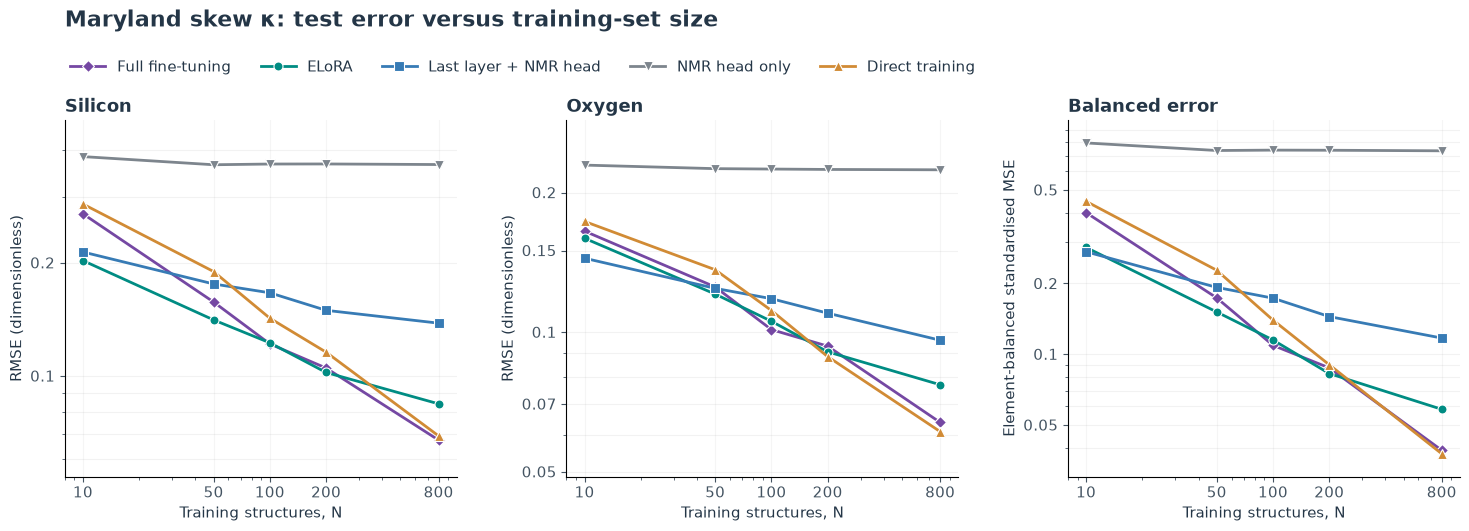

N                                  10      50      100     200     800
Element  Method                                                       
Si       Full fine-tuning       0.2699  0.1573  0.1217  0.1050  0.0675
         ELoRA                  0.2027  0.1410  0.1225  0.1022  0.0843
         Last layer + NMR head  0.2137  0.1757  0.1664  0.1495  0.1382
         NMR head only          0.3832  0.3645  0.3662  0.3663  0.3650
         Direct training        0.2866  0.1896  0.1425  0.1157  0.0693
O        Full fine-tuning       0.1652  0.1252  0.1013  0.0933  0.0639
         ELoRA                  0.1594  0.1208  0.1056  0.0907  0.0770
         Last layer + NMR head  0.1444  0.1243  0.1181  0.1099  0.0961
         NMR head only          0.2293  0.2252  0.2248  0.2244  0.2240
         Direct training        0.1733  0.1364  0.1114  0.0886  0.0610
balanced Full fine-tuning       0.4003  0.1737  0.1091  0.0875  0.0390
         ELoRA                  0.2847  0.1513  0.1150  0.0828  0.0583
         Last layer + NMR head  0.2729  0.1925  0.1732  0.1446  0.1172
         NMR head only          0.7925  0.7358  0.7386  0.7377  0.7336
         Direct training        0.4471  0.2277  0.1398  0.0902  0.0377

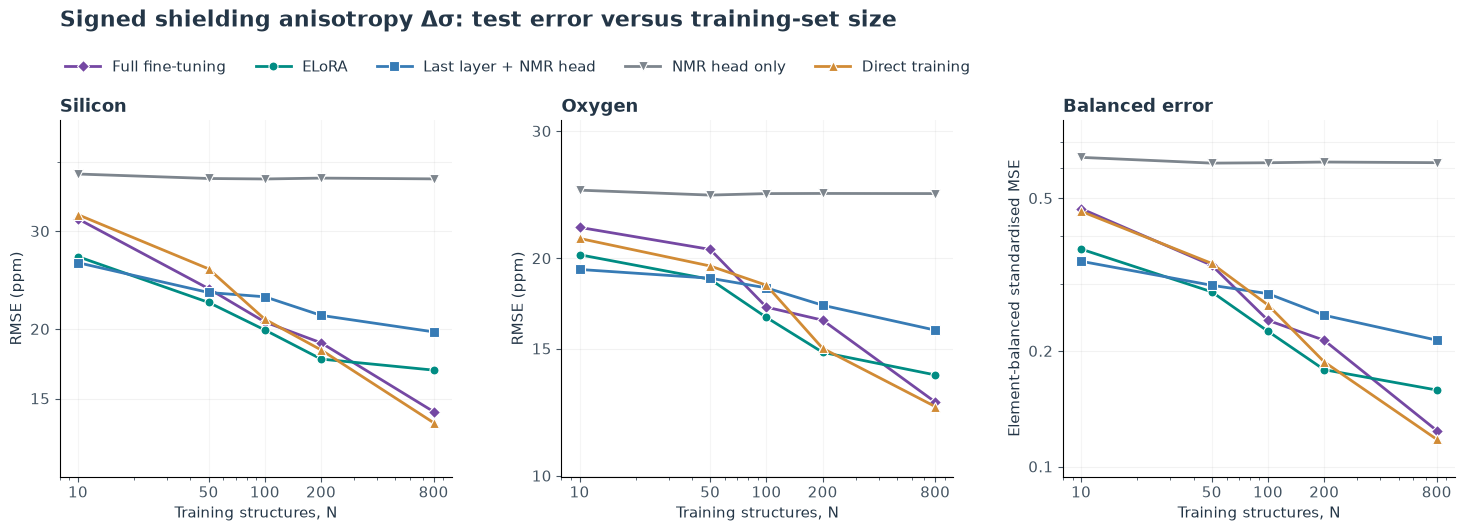

N                                   10       50       100      200      800
Element  Method                                                            
Si       Full fine-tuning       31.5936  23.6592  20.6055  18.9017  14.2122
         ELoRA                  27.0168  22.3472  19.9357  17.6724  16.8804
         Last layer + NMR head  26.3460  23.2842  22.8743  21.1801  19.7790
         NMR head only          38.0429  37.3426  37.2692  37.4036  37.2840
         Direct training        32.1436  25.6815  20.8414  18.3542  13.5761
O        Full fine-tuning       22.0861  20.5865  17.1278  16.4293  12.6582
         ELoRA                  20.2417  18.7139  16.5746  14.8288  13.7988
         Last layer + NMR head  19.3134  18.7813  18.2104  17.2310  15.9167
         NMR head only          24.8673  24.4802  24.5958  24.6075  24.5974
         Direct training        21.3209  19.5264  18.3651  15.0179  12.4751
balanced Full fine-tuning        0.4701   0.3348   0.2406   0.2134   0.1243
         ELoRA                   0.3689   0.2855   0.2253   0.1789   0.1584
         Last layer + NMR head   0.3429   0.2969   0.2824   0.2481   0.2137
         NMR head only           0.6394   0.6178   0.6191   0.6218   0.6194
         Direct training         0.4627   0.3385   0.2638   0.1875   0.1179

Opposite-sign Δσ percentage on the test set (%):


N                                10     50     100    200    800
Element Method                                                  
Si      Full fine-tuning       18.31   9.50   7.60   6.86   4.08
        ELoRA                  13.81   9.10   7.81   6.36   5.44
        Last layer + NMR head  14.29  11.19  10.61   9.72   8.82
        NMR head only          28.89  27.40  27.28  27.22  27.14
        Direct training        19.82  12.01   8.60   7.14   4.10
O       Full fine-tuning        3.11   2.33   1.68   1.64   1.06
        ELoRA                   2.94   2.15   1.80   1.54   1.22
        Last layer + NMR head   2.46   2.18   2.06   1.92   1.75
        NMR head only           3.78   3.66   3.68   3.67   3.66
        Direct training         3.01   2.44   2.02   1.60   1.05

In [6]:
fig = plot_parameter_curves(curves, 'skew', 'test')
save_figure(fig, FIGURES, 'test-skew-learning-curves')
plt.show()
display(rmse_table(curves, 'skew', 'test'))

fig = plot_parameter_curves(curves, 'anisotropy', 'test')
save_figure(fig, FIGURES, 'test-anisotropy-learning-curves')
plt.show()
display(rmse_table(curves, 'anisotropy', 'test'))
print('Opposite-sign Δσ percentage on the test set (%):')
display(sign_flip_table(DATA, 'test').round(2))

## Validation curves

The validation set chose the checkpoints, so these curves are not independent of model selection. They are shown to confirm that the test trends are consistent across the three headline parameters.

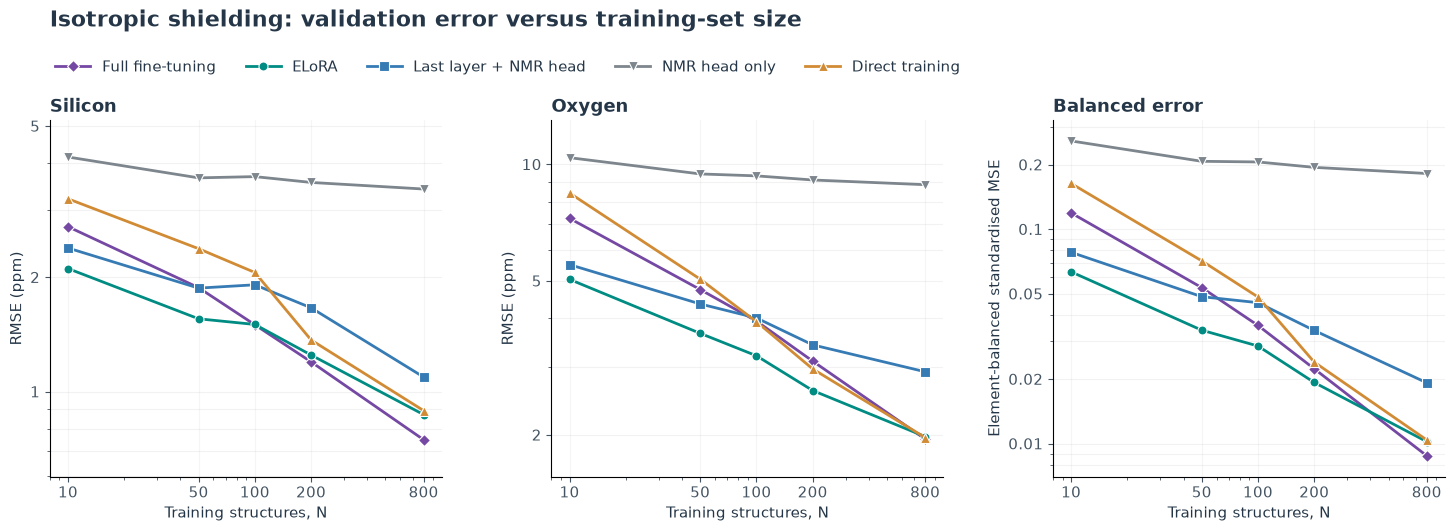

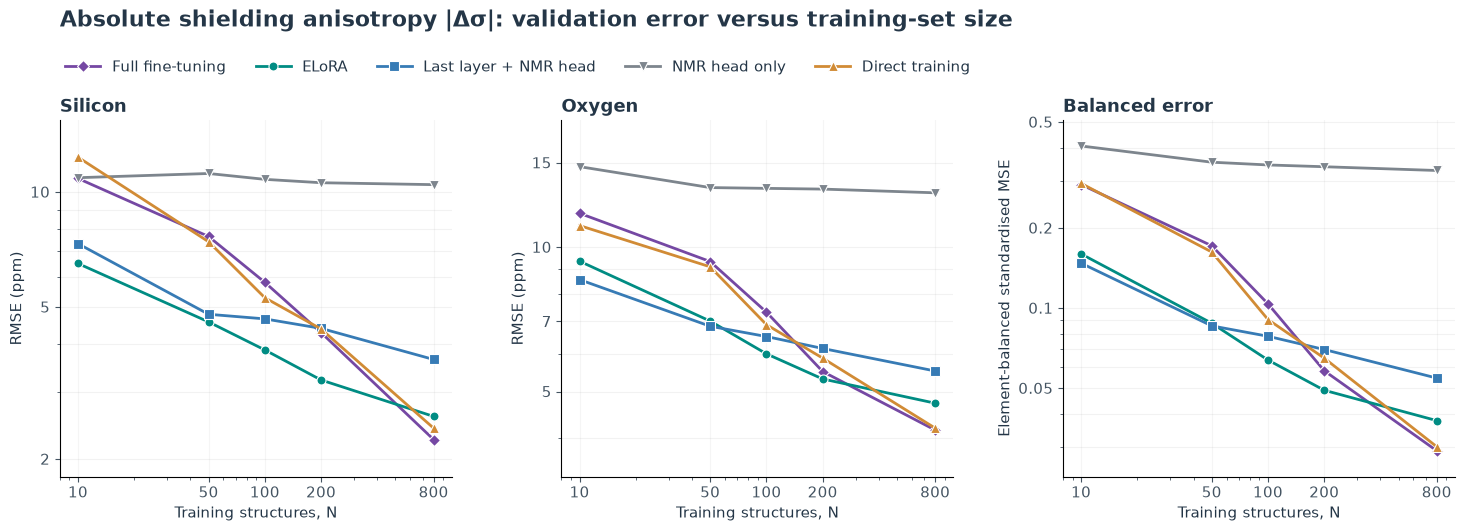

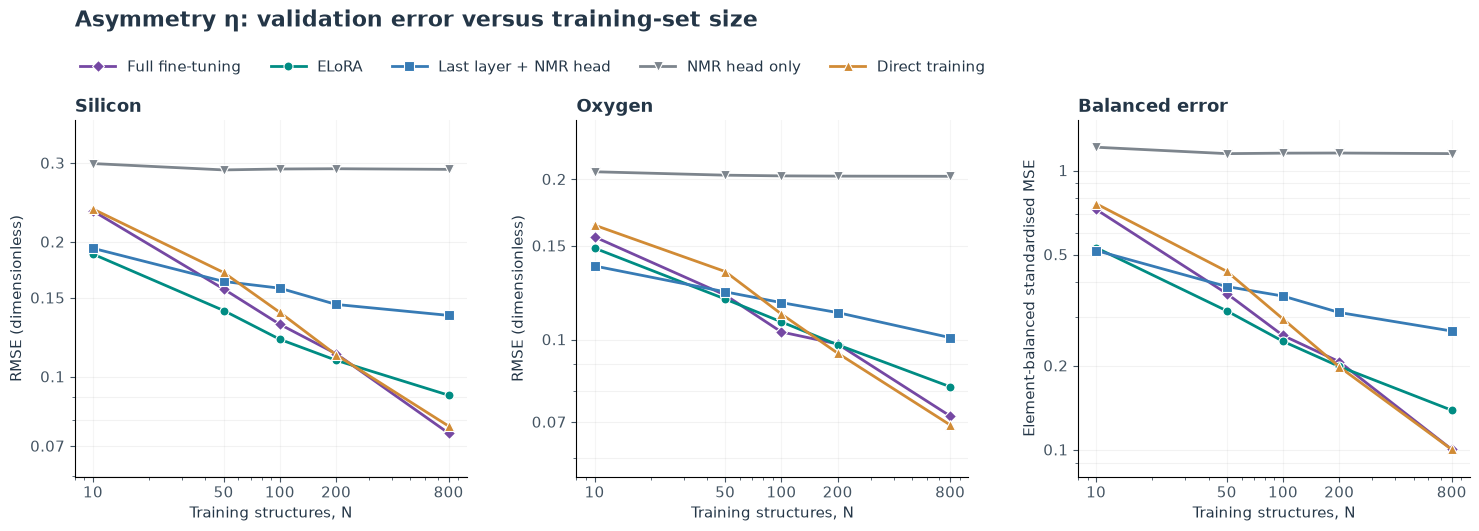

In [7]:
for q, stem in [('isotropy', 'validation-isotropy-learning-curves'),
                ('abs_anisotropy', 'validation-abs-anisotropy-learning-curves'),
                ('asymmetry', 'validation-asymmetry-learning-curves')]:
    fig = plot_parameter_curves(curves, q, 'validation')
    save_figure(fig, FIGURES, stem)
    plt.show()

## Interpretation

Single-seed (seed 42) results across all 25 converged runs on the 150-structure test set.

- **Pretraining helps most when labelled NMR data are scarce (N ≤ 100), for both isotropic shielding and tensor shape.**
  - At N10, ELoRA reduces balanced σiso error by 58% relative to direct training (0.049 vs 0.117; Si 1.87 vs 2.89 ppm, O 4.40 vs 6.80 ppm) and cuts Si |Δσ| RMSE by 47% (5.34 vs 10.05 ppm).
  - At N50, ELoRA beats direct training at N100 on σiso (balanced 0.022 vs 0.028; Si 1.24 vs 1.52 ppm, O 3.01 vs 3.09 ppm) and on |Δσ| (balanced 0.048 vs 0.056; Si 3.45 vs 4.17 ppm, O 5.16 vs 5.41 ppm).
- **ELoRA leads from N10 to N200, then full-backbone methods overtake it at N800.**
  - From N50 to N200, ELoRA has the lowest balanced error on σiso, |Δσ| and η (except η at N100, where full fine-tuning is marginally lower at 0.208 vs 0.218).
  - At N800, full fine-tuning and direct training both outperform ELoRA across every parameter: balanced σiso reaches 0.0056 for both full fine-tuning (Si 0.68, O 1.40 ppm) and direct training (Si 0.63, O 1.52 ppm) versus 0.0067 for ELoRA (Si 0.66, O 1.68 ppm); balanced |Δσ| reaches 0.0137 (full fine-tuning: Si 1.54, O 2.86 ppm) and 0.0147 (direct training: Si 1.75, O 2.91 ppm) versus 0.0196 for ELoRA (Si 2.07, O 3.34 ppm); balanced η reaches 0.077 (direct) and 0.079 (full fine-tuning) versus 0.114 (ELoRA). This matches a regularisation-versus-capacity trade-off: rank-4 adapters (~3% trainable parameters) protect against overfitting at small N but become a bottleneck once 800 structures are available.
- **Last layer + NMR head is competitive at N10, then levels off.** It achieves the lowest balanced |Δσ| (0.087), η (0.479) and κ (0.273) at N10, but by N200–800 it trails all three full-backbone methods clearly.
- **NMR head only hits a hard representational floor even when fully converged.** Resuming with a raised epoch ceiling allowed all five head-only runs to reach early stopping (between epoch 2,781 at N800 and 17,343 at N10), which substantially improved the previously under-converged N10 point (Si σiso 6.79 → 3.57 ppm, O 14.12 → 9.20 ppm). Even so, the curve is nearly flat from N50 to N800 (Si σiso 3.26 → 3.01 ppm; Si |Δσ| 10.30 → 9.53 ppm; balanced η ≈ 1.09, slightly worse than predicting the training-pool mean). Frozen E/F features alone do not capture the shielding tensor's magnitude or shape.
- **Using |Δσ| instead of signed Δσ exposes the real tensor-shape accuracy.** Opposite-sign Δσ flips near η ≈ 1 affect 4.1–28.9% of Si atoms and 1.1–3.8% of O atoms, inflating signed Δσ RMSE by 4–9× (for example, full fine-tuning N800 Si drops from 14.21 ppm signed to 1.54 ppm for |Δσ|). Maryland skew κ confirms the same method ordering when sign information is kept smoothly.

Caveats: every point is a single seed (seed 42), and full fine-tuning used a lower untuned learning rate (1e-4) than the other methods (3e-3), so narrow differences between full fine-tuning, ELoRA and direct training at N100–200 and between full fine-tuning and direct training at N800 sit within plausible seed-to-seed variance.